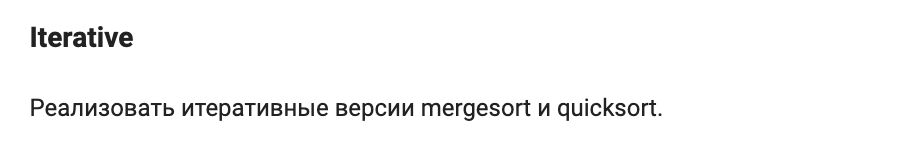


# Ход решения

## Итеративный Merge Sort (Bottom-Up)

В обычном рекурсивном Merge Sort мы сначала делим массив пополам, а затем объединяем отсортированные части. В итеративной версии поступаем наоборот: начинаем с маленьких отсортированных блоков и постепенно объединяем их в более крупные, пока не получим полностью отсортированный массив. Рекурсия здесь не нужна, поскольку мы самостоятельно управляем размером объединяемых блоков.

Для хранения элементов используется обычный список Python (`list`). Сначала создаём копию исходного массива с помощью `arr.copy()`, чтобы не изменять входные данные. Затем вводим переменную `width = 1`, которая обозначает текущую длину отсортированного блока. Изначально считаем каждый элемент отдельным отсортированным блоком длины 1, поскольку один элемент всегда отсортирован.

Далее запускаем цикл `while width < len(result)`. На каждой его итерации проходим по массиву и объединяем соседние блоки длины `width`. Для этого используем цикл `for start in range(0, len(result), 2 * width)`, который перемещает нас по массиву с шагом `2 * width`, то есть сразу на длину двух соседних блоков.

На каждой итерации выделяем два подмассива:

- `left = result[start:start + width]` — левый отсортированный блок.
- `right = result[start + width:start + 2 * width]` — правый отсортированный блок.

Затем передаём их в функцию `merge(left, right)`, которая объединяет два отсортированных списка в один. Для этого используются два указателя: `i` для левого списка и `j` для правого. Сравниваем элементы `left[i]` и `right[j]`, добавляем меньший в результирующий список и увеличиваем соответствующий указатель. Поскольку оба блока уже отсортированы, нет необходимости сравнивать каждый элемент с каждым — достаточно рассматривать первые ещё не использованные элементы. Когда один из блоков заканчивается, оставшиеся элементы другого добавляются в конец.

Результаты слияний последовательно добавляются в новый список `merged` с помощью `extend()`. После завершения прохода заменяем `result` на `merged` и увеличиваем размер блока вдвое: `width *= 2`. Таким образом, на каждом следующем проходе объединяем всё более крупные отсортированные участки.

**Пример работы:**

Исходный массив:

`[7, 2, 9, 4, 1, 8, 5, 3]`

**Первый проход (`width = 1`).** Каждый элемент рассматривается как отдельный отсортированный блок. Объединяем соседние элементы попарно:

`[7] + [2] → [2, 7]`

`[9] + [4] → [4, 9]`

`[1] + [8] → [1, 8]`

`[5] + [3] → [3, 5]`

Получаем `[2, 7, 4, 9, 1, 8, 3, 5]`.

**Второй проход (`width = 2`).** Теперь объединяем соседние отсортированные блоки по два элемента:

`[2, 7] + [4, 9] → [2, 4, 7, 9]`

`[1, 8] + [3, 5] → [1, 3, 5, 8]`

Получаем `[2, 4, 7, 9, 1, 3, 5, 8]`.

**Третий проход (`width = 4`).** Объединяем два отсортированных блока по четыре элемента:

`[2, 4, 7, 9] + [1, 3, 5, 8]`

Получаем `[1, 2, 3, 4, 5, 7, 8, 9]`.

После этого `width` становится равным 8, то есть длине массива, и цикл завершается.

Таким образом, в итеративном Merge Sort используются обычные списки Python для хранения элементов и результатов слияния, а также переменные `width` и `start` для управления границами блоков. Отдельный стек не нужен, поскольку все действия организованы с помощью циклов.

Если длина массива нечётная или последний блок не имеет пары, функция `merge` корректно обработает пустой правый блок. Для пустого массива и массива из одного элемента основной цикл вообще не выполняется.

## Итеративный Quick Sort

В рекурсивном Quick Sort мы выбираем опорный элемент (`pivot`), разделяем массив относительно него и рекурсивно сортируем получившиеся части. В итеративной версии принцип сортировки остаётся тем же, но вместо рекурсивных вызовов мы самостоятельно храним информацию о подмассивах, которые ещё необходимо обработать.

Для этого используется **стек (stack)** — структура данных, работающая по принципу LIFO (Last In, First Out), то есть последний добавленный элемент извлекается первым. В Python стек удобно реализовать обычным списком (`list`):

- `stack.append(x)` — добавляет элемент на вершину стека.
- `stack.pop()` — извлекает последний добавленный элемент.

В нашем случае элементами стека являются кортежи `(left, right)`, содержащие индексы начала и конца подмассива. Мы не создаём отдельные списки для каждой части, а храним только их границы и выполняем перестановки непосредственно в рабочем массиве.

Сначала создаём копию исходного массива `result = arr.copy()`, чтобы не изменять входные данные. Затем помещаем в стек границы всего массива: `stack = [(0, len(result) - 1)]`.

Далее запускаем цикл `while stack`, который выполняется, пока в стеке остаются необработанные подмассивы. На каждой итерации извлекаем последний добавленный отрезок с помощью `left, right = stack.pop()`. Если `left >= right`, отрезок содержит не более одного элемента, поэтому сортировать его не нужно.

В противном случае вызываем функцию `partition(result, left, right)`, которая выполняет разбиение относительно опорного элемента. В качестве `pivot` выбираем последний элемент текущего подмассива — `arr[right]`.

Для разбиения используются два указателя:

- `j` последовательно просматривает элементы текущего подмассива слева направо.
- `i` указывает на позицию, куда необходимо поставить следующий найденный элемент меньше `pivot`.

Если `arr[j] < pivot`, меняем местами элементы `arr[i]` и `arr[j]`, после чего увеличиваем `i`. Если элемент больше или равен `pivot`, просто продолжаем просмотр, не изменяя `i`.

После завершения прохода меняем `pivot` с элементом на позиции `i`. В результате слева от него находятся все элементы меньше опорного, а справа — элементы больше или равные ему. Функция `partition` возвращает индекс `pivot_idx`, на котором опорный элемент теперь находится окончательно.

После разбиения получаем два новых подмассива:

- `a = (left, pivot_idx - 1)` — левая часть.
- `b = (pivot_idx + 1, right)` — правая часть.

Их необходимо отсортировать аналогичным образом, поэтому добавляем соответствующие границы обратно в стек. При этом сохраняем только отрезки, содержащие хотя бы два элемента (`lo < hi`).

**Важная оптимизация — порядок добавления в стек.** Мы сначала сравниваем размеры двух получившихся частей и при необходимости меняем местами переменные `a` и `b`, чтобы `a` обозначал больший отрезок, а `b` — меньший.

Затем сначала добавляем в стек больший отрезок, а после него — меньший. Поскольку стек работает по принципу LIFO, меньший отрезок будет извлечён и обработан первым, а больший останется ожидать своей очереди.

Такой порядок позволяет ограничить количество одновременно хранящихся отрезков. Когда мы откладываем большую часть и продолжаем обработку меньшей, размер текущей задачи уменьшается как минимум примерно вдвое. Благодаря этому размер явного стека остаётся $O(\log n)$ даже при несбалансированных разбиениях.

**Пример работы:**

Исходный массив:

`[7, 2, 9, 4, 1, 8, 5, 3]`

Начальное состояние стека:

`stack = [(0, 7)]`

**Первая итерация.** Извлекаем `(0, 7)` и выбираем `pivot = 3`. После выполнения `partition` получаем:

`[2, 1, 3, 4, 7, 8, 5, 9]`

Опорный элемент 3 оказался на индексе 2. Получились два подмассива:

- Левый: индексы `(0, 1)`, элементы `[2, 1]`.
- Правый: индексы `(3, 7)`, элементы `[4, 7, 8, 5, 9]`.

Сначала добавляем больший отрезок, затем меньший:

`stack = [(3, 7), (0, 1)]`

**Вторая итерация.** Из стека извлекается `(0, 1)`, поскольку он был добавлен последним. Для подмассива `[2, 1]` выбираем `pivot = 1`. После разбиения получаем:

`[1, 2, 3, 4, 7, 8, 5, 9]`

Новые части содержат не более одного элемента, поэтому ничего не добавляем в стек. Теперь в нём остался только `(3, 7)`.

**Третья итерация.** Извлекаем `(3, 7)` и выбираем `pivot = 9`. Это максимальный элемент текущего подмассива, поэтому после разбиения он остаётся справа. Получаем левый отрезок `(3, 6)`, который добавляем в стек.

**Четвёртая итерация.** Обрабатываем `(3, 6)`, то есть `[4, 7, 8, 5]`. Выбираем `pivot = 5`. После разбиения массив принимает вид:

`[1, 2, 3, 4, 5, 8, 7, 9]`

Остаётся неотсортированный отрезок `(5, 6)` с элементами `[8, 7]`.

**Пятая итерация.** Обрабатываем `[8, 7]` с `pivot = 7`. После разбиения получаем:

`[1, 2, 3, 4, 5, 7, 8, 9]`

Новых отрезков для обработки не осталось, стек пуст, поэтому сортировка завершается.

Таким образом, итеративный Quick Sort использует обычный список Python в качестве стека, кортежи для хранения границ подмассивов и два указателя для выполнения `partition`. В отличие от рекурсивной версии, управление очередностью обработки частей полностью реализовано вручную.

## Дополнительные особенности реализации

Обе функции возвращают отсортированную копию исходного массива, поэтому перед сортировкой вызывается `arr.copy()`.

Также предусмотрен необязательный параметр `trace`, который используется для визуализации работы алгоритмов. Если он передан, функция сохраняет промежуточные состояния:

- **Merge Sort:** текущую ширину блоков и копию массива после каждого полного прохода.
- **Quick Sort:** границы обработанного подмассива, индекс `pivot`, состояние массива и содержимое стека после разбиения.

Это позволяет наглядно увидеть последовательность действий алгоритмов без изменения их основной логики. При этом сохранение промежуточных копий массива требует дополнительной памяти, поэтому оценки пространственной сложности рассматриваются для обычного запуска без `trace`.

# Граничные случаи

- Пустой список и один элемент: ни одного слияния/разбиения, результат — копия.
- Нечётный размер массива: в Merge Sort последний блок может не иметь пары — сливаем с пустым блоком.
- Дубликаты и отрицательные значения: обрабатываются без особых правил.
- У Quick Sort на отсортированном массиве с последним `pivot` возможно $O(n^2)$, **но `RecursionError` уже не возникает**, поскольку используется собственный стек.

# Сложность алгоритмов

| Алгоритм | Время в среднем | Худшее время | Дополнительная память |
| --- | --- | --- | --- |
| Iterative Merge Sort | $O(n\log n)$ | $O(n\log n)$ | $O(n)$ |
| Iterative Quick Sort | $O(n\log n)$ | $O(n^2)$ | $O(n)$ с учётом копии входа; стек — $O(\log n)$ |

У Merge Sort $O(\log n)$ проходов, каждый обрабатывает $n$ элементов. У Quick Sort разбиение линейно от размера текущего подмассива, а суммарная стоимость зависит от баланса `pivot`. Благодаря обработке **меньшей части первой** размер нашего явного стека не превосходит $O(\log n)$ даже при неудачных разбиениях. Режим `trace` дополнительно сохраняет снимки массива и не учитывается в оценках основного алгоритма.

**Замечание о памяти:** `quick_sort_iterative` создаёт `arr.copy()`, поэтому полная дополнительная память составляет $O(n)$. При этом **сам явный стек** занимает не более $O(\log n)$ благодаря обработке меньшего отрезка первым. Если сортировать исходный массив без копии, общая вспомогательная память ограничивалась бы стеком.


# Реализация алгоритмов

In [1]:
def merge(left, right):
    result = []
    i = j = 0

    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

    return result + left[i:] + right[j:]


def merge_sort_iterative(arr, trace=None):
    result = arr.copy()
    width = 1

    if trace is not None:
        trace.append((0, result.copy()))

    while width < len(result):
        merged = []

        for start in range(0, len(result), 2 * width):
            left = result[start:start + width]
            right = result[start + width:start + 2 * width]
            merged.extend(merge(left, right))

        result = merged

        if trace is not None:
            trace.append((width, result.copy()))

        width *= 2

    return result


def partition(arr, left, right):
    pivot = arr[right]
    i = left

    for j in range(left, right):
        if arr[j] < pivot:
            arr[i], arr[j] = arr[j], arr[i]
            i += 1

    arr[i], arr[right] = arr[right], arr[i]
    return i


def quick_sort_iterative(arr, trace=None):
    result = arr.copy()
    stack = [(0, len(result) - 1)]

    while stack:
        left, right = stack.pop()
        if left >= right:
            continue

        pivot_idx = partition(result, left, right)
        a = (left, pivot_idx - 1)
        b = (pivot_idx + 1, right)

        if a[1] - a[0] < b[1] - b[0]:
            a, b = b, a

        for lo, hi in (a, b):
            if lo < hi:
                stack.append((lo, hi))

        if trace is not None:
            trace.append((left, right, pivot_idx, result.copy(), stack.copy()))

    return result

# Проверка на нетривиальном примере

Используем `[7, 2, 9, 4, 1, 8, 5, 3]`.

**Iterative Merge Sort:**

| Проход | Ширина блока до слияния | Массив после прохода |
| --- | --- | --- |
| Начало | 0 | `[7, 2, 9, 4, 1, 8, 5, 3]` |
| 1 | 1 | `[2, 7, 4, 9, 1, 8, 3, 5]` |
| 2 | 2 | `[2, 4, 7, 9, 1, 3, 5, 8]` |
| 3 | 4 | `[1, 2, 3, 4, 5, 7, 8, 9]` |

**Iterative Quick Sort:** на первом разбиении `pivot = 3`, получаем `[2, 1, 3, 4, 7, 8, 5, 9]`. После него в стек попадут отрезки `(3, 7)` и `(0, 1)`; первым будет обработан меньший `(0, 1)`. Затем аналогично обрабатываются оставшиеся части. Следующая ячейка печатает **реальные состояния и стек нашей реализации**.

In [2]:
example = [7, 2, 9, 4, 1, 8, 5, 3]
merge_trace = []
quick_trace = []
merge_result = merge_sort_iterative(example, trace=merge_trace)
quick_result = quick_sort_iterative(example, trace=quick_trace)

print('Iterative Merge Sort:')
for width, values in merge_trace:
    print(f'  width={width}: {values}')

print('\nIterative Quick Sort:')
for left, right, pivot_idx, values, stack in quick_trace:
    print(f'  отрезок [{left}:{right}], pivot_idx={pivot_idx}: {values}, стек={stack}')

assert merge_result == quick_result == sorted(example)
print('\nРезультат:', merge_result)

Iterative Merge Sort:
  width=0: [7, 2, 9, 4, 1, 8, 5, 3]
  width=1: [2, 7, 4, 9, 1, 8, 3, 5]
  width=2: [2, 4, 7, 9, 1, 3, 5, 8]
  width=4: [1, 2, 3, 4, 5, 7, 8, 9]

Iterative Quick Sort:
  отрезок [0:7], pivot_idx=2: [2, 1, 3, 4, 7, 8, 5, 9], стек=[(3, 7), (0, 1)]
  отрезок [0:1], pivot_idx=0: [1, 2, 3, 4, 7, 8, 5, 9], стек=[(3, 7)]
  отрезок [3:7], pivot_idx=7: [1, 2, 3, 4, 7, 8, 5, 9], стек=[(3, 6)]
  отрезок [3:6], pivot_idx=4: [1, 2, 3, 4, 5, 8, 7, 9], стек=[(5, 6)]
  отрезок [5:6], pivot_idx=5: [1, 2, 3, 4, 5, 7, 8, 9], стек=[]

Результат: [1, 2, 3, 4, 5, 7, 8, 9]


# Визуализация работы алгоритмов

Ниже состояния построены из массива `example` и трассировки **самих функций**, а не вручную подготовленных результатов.

- **Merge Sort:** на каждой строке виден массив после очередного прохода; ширина отсортированного блока удваивается.
- **Quick Sort:** каждая строка — состояние после `partition`; пунктиром показана позиция очередного `pivot`, который теперь находится на окончательном месте. Последовательность отрезков определяет стек, а не рекурсия.

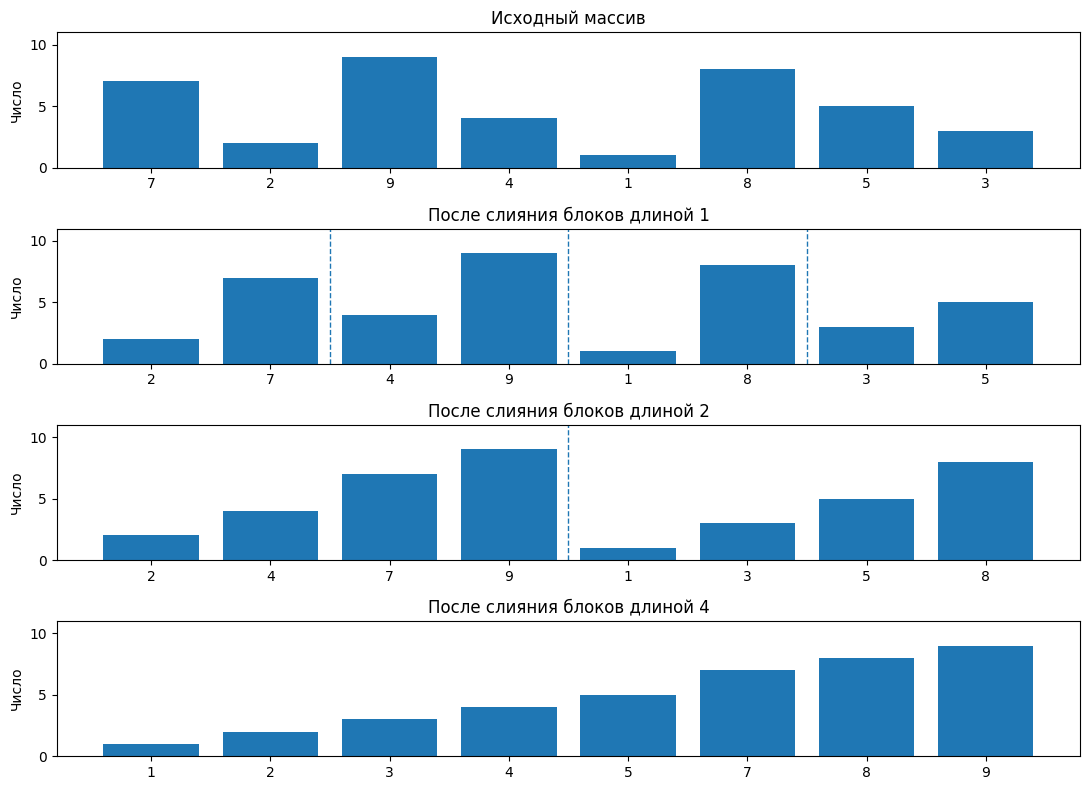

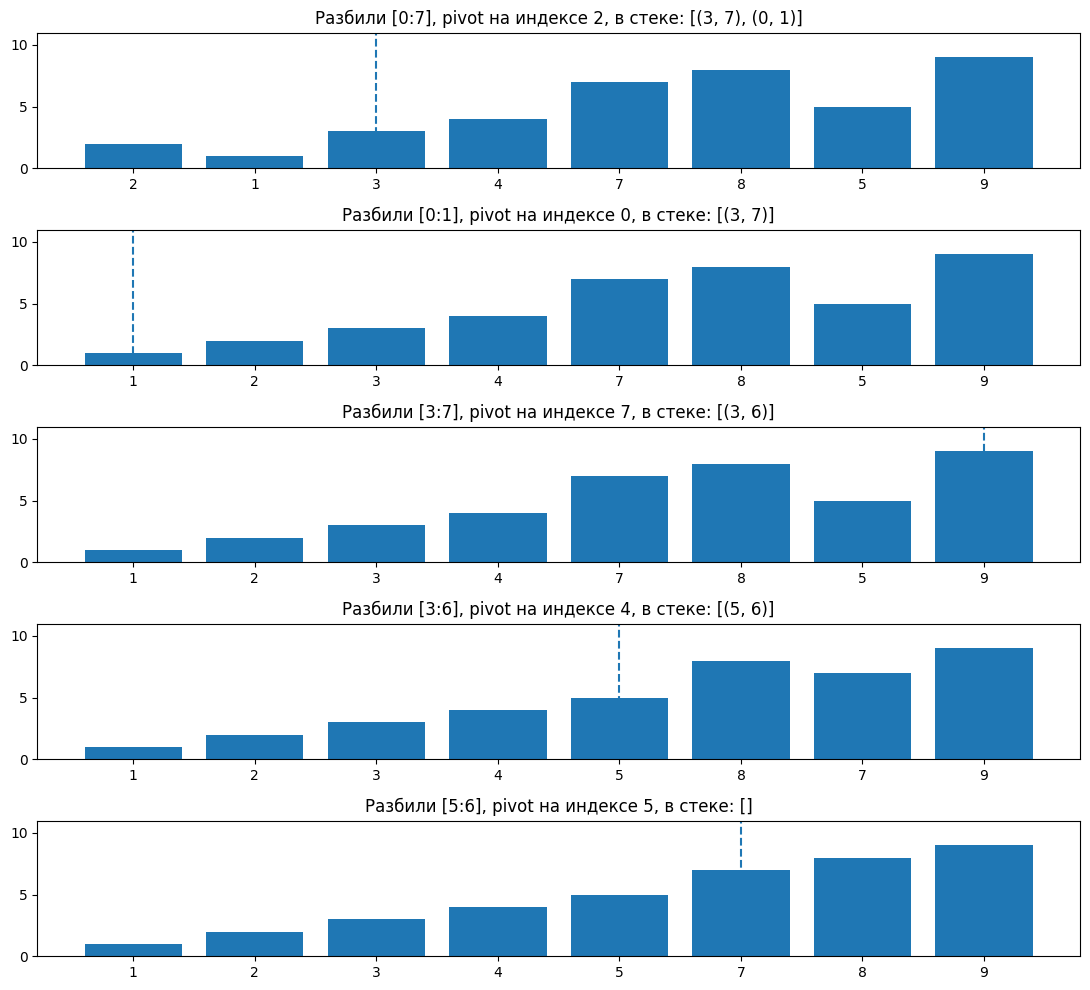

In [3]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(len(merge_trace), 1, figsize=(11, 8))
for ax, (width, values) in zip(axes, merge_trace):
    ax.bar(range(len(values)), values)
    ax.set_xticks(range(len(values)), values)
    ax.set_ylim(0, max(example) + 2)
    ax.set_ylabel('Число')
    ax.set_title('Исходный массив' if width == 0 else f'После слияния блоков длиной {width}')
    if width:
        for boundary in range(2 * width, len(values), 2 * width):
            ax.axvline(boundary - 0.5, linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(quick_trace), 1, figsize=(11, max(3, len(quick_trace) * 2)))
if len(quick_trace) == 1:
    axes = [axes]

for ax, (left, right, pivot_idx, values, stack) in zip(axes, quick_trace):
    ax.bar(range(len(values)), values)
    ax.axvline(pivot_idx, linestyle='--')
    ax.set_xticks(range(len(values)), values)
    ax.set_ylim(0, max(example) + 2)
    ax.set_title(f'Разбили [{left}:{right}], pivot на индексе {pivot_idx}, в стеке: {stack}')
plt.tight_layout()
plt.show()

# Тесты

Проверим:
- пустой массив, один и два элемента;
- отсортированные, обратные и одинаковые значения;
- отрицательные числа, ноль, дубликаты;
- нечётные размеры, когда у последнего блока Merge Sort нет пары;
- массивы случайного размера и содержания;
- большие входы (в том числе отсортированный массив длиной `1500` для Quick Sort — без рекурсивного ограничения);
- сохранность оригинала и корректность трассировки.

In [4]:
import random
import unittest


class TestIterativeSorts(unittest.TestCase):
    algorithms = (merge_sort_iterative, quick_sort_iterative)

    def check(self, values):
        expected = sorted(values)

        for algorithm in self.algorithms:
            with self.subTest(algorithm=algorithm.__name__, size=len(values)):
                original = values.copy()
                self.assertEqual(algorithm(values), expected)
                self.assertEqual(values, original)

    def test_empty_and_singleton(self):
        self.check([])
        self.check([10])

    def test_pairs(self):
        for values in ([2, 1], [1, 2], [5, 5]):
            self.check(values)

    def test_odd_lengths(self):
        for values in ([4, 1, 3], [7, 0, 5, -1, 2], [9, 4, 3, 2, 1, 0, 8]):
            self.check(values)

    def test_duplicates_and_negatives(self):
        self.check([0, -3, 5, -3, 9, 5, 5, 2, 0])
        self.check([7] * 100)

    def test_ordered_and_reversed(self):
        self.check(list(range(250)))
        self.check(list(range(249, -1, -1)))

    def test_large_sorted_without_recursion(self):
        self.check(list(range(1500)))

    def test_random_arrays(self):
        rng = random.Random(15)
        for size in (3, 8, 27, 100, 500, 2000):
            self.check([rng.randint(-1000, 1000) for _ in range(size)])

    def test_traces(self):
        values = [7, 2, 9, 4, 1, 8, 5, 3]
        merge_steps, quick_steps = [], []
        self.assertEqual(merge_sort_iterative(values, merge_steps), sorted(values))
        self.assertEqual(quick_sort_iterative(values, quick_steps), sorted(values))
        self.assertEqual([w for w, _ in merge_steps], [0, 1, 2, 4])
        self.assertTrue(quick_steps)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestIterativeSorts)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_duplicates_and_negatives (__main__.TestIterativeSorts.test_duplicates_and_negatives) ... ok
test_empty_and_singleton (__main__.TestIterativeSorts.test_empty_and_singleton) ... ok
test_large_sorted_without_recursion (__main__.TestIterativeSorts.test_large_sorted_without_recursion) ... ok
test_odd_lengths (__main__.TestIterativeSorts.test_odd_lengths) ... ok
test_ordered_and_reversed (__main__.TestIterativeSorts.test_ordered_and_reversed) ... ok
test_pairs (__main__.TestIterativeSorts.test_pairs) ... ok
test_random_arrays (__main__.TestIterativeSorts.test_random_arrays) ... ok
test_traces (__main__.TestIterativeSorts.test_traces) ... ok

----------------------------------------------------------------------
Ran 8 tests in 0.558s

OK
